# Suffix prediction with procedural background knowledge

This tutorial shows how to combine a neural next-activity model with a procedural background-knowledge (BK) model during beam-search suffix prediction. The feedback split is used to select the modulation weight, while the test split remains untouched until the final evaluation.

## Reproducibility

Set a fixed random seed before loading the data, encoding prefixes, or creating the neural model. Run the notebook from top to bottom so that the data split, BK model, checkpoint, feedback selection, and test predictions all refer to the same experiment.

In [1]:
import keras

SEED = 42
keras.utils.set_random_seed(SEED)

if keras.backend.backend() == 'tensorflow':
    import tensorflow as tf
    tf.config.experimental.enable_op_determinism()

print(f'Using random seed: {SEED}')

Using random seed: 42


# 1. Data preparation

The preparation stage creates a trace-level train/feedback/test split, identifies rare or unseen feedback variants, discovers a procedural BK model from those variants, and encodes the training prefixes for the neural model. The test traces are not used by any of these steps.

## 1.1 Data split

LogData orders cases by the timestamp of their first event and assigns complete cases to each partition. With `train_ratio=0.7` and `feedback_ratio=0.1`, $70%$ of cases are used for initial neural training, $10%$ for feedback set for discovering BK and tuning the weight, and the remaining $20%$ are held out for testing.

The split is also exported as `log_name_train.xes`, `log_name_feedback.xes`, and `log_name_test.xes`.

In [3]:
from pathlib import Path

from NeSy4PPM.Data_preprocessing.log_utils import LogData

log_path = Path.cwd().parent / 'data' / 'input' / 'logs'
log_name = 'helpdesk'
log_file = f'{log_name}.xes'

log_data = LogData(log_path=log_path, log_name=log_file,train_ratio=0.7,feedback_ratio=0.1)

print(f'Train/feedback maximum trace length: {log_data.max_len}')
print(f'Entire event-log maximum trace length: {log_data.max_len_log}')

exporting log, completed traces :: 100%|██████████| 3206/3206 [00:00<00:00, 29244.94it/s]


Training log saved to /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/input/logs/helpdesk_train.xes


exporting log, completed traces :: 100%|██████████| 457/457 [00:00<00:00, 29449.77it/s]


Feedback log saved to /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/input/logs/helpdesk_feedback.xes


exporting log, completed traces :: 100%|██████████| 917/917 [00:00<00:00, 28279.67it/s]


Test log saved to /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/input/logs/helpdesk_test.xes
new activities un-found in the training set ['DUPLICATE']
new activities un-found in the feedback set ['Schedule intervention', 'Resolve SW anomaly', 'DUPLICATE']
Train/feedback maximum trace length: 15
Entire event-log maximum trace length: 15


## 1.2 Filter feedback variants for BK discovery

`filter_feedback_for_bk_discovery` computes the support of each activity variant $v$ using only the training traces. A feedback trace is retained if its variant is absent from the training set or has a training support below the configured threshold of 10%. This filtering makes rare and previously unseen behavior available for procedural BK discovery without using information from the test set. The retained traces are saved to `log_name_feedback_filtered.xes`.

In [4]:
from NeSy4PPM.Data_preprocessing.utils import filter_feedback_for_bk_discovery

feedback_log_path = log_path / f'{log_name}_feedback.xes'
train_log_path = log_path / f'{log_name}_train.xes'
filtered_feedback_log_path = log_path / f'{log_name}_feedback_filtered.xes'

filtered_feedback_path = filter_feedback_for_bk_discovery(train_log_path=train_log_path,feedback_log_path=feedback_log_path,filtered_feedback_log_path=filtered_feedback_log_path,max_train_variant_support_ratio=0.1)

exporting log, completed traces :: 100%|██████████| 152/152 [00:00<00:00, 24504.52it/s]


Filtered feedback BK source: 152/457 cases, 27/28 variants


## 1.3 Discover the procedural BK

The procedural BK is learned from the filtered feedback log. `discover_procedural_model` discovers an inductive BPMN model and converts it to the Petri-net representation consumed by suffix prediction and fitness evaluation.

The returned process_model contains the net, initial and final markings, and the BK type. Use a `.pnml` filename to write a Petri net directly; the `.bpmn` filename below follows the default BPMN-to-Petri-net conversion path.

parsing log, completed traces :: 100%|██████████| 152/152 [00:00<00:00, 14829.14it/s]


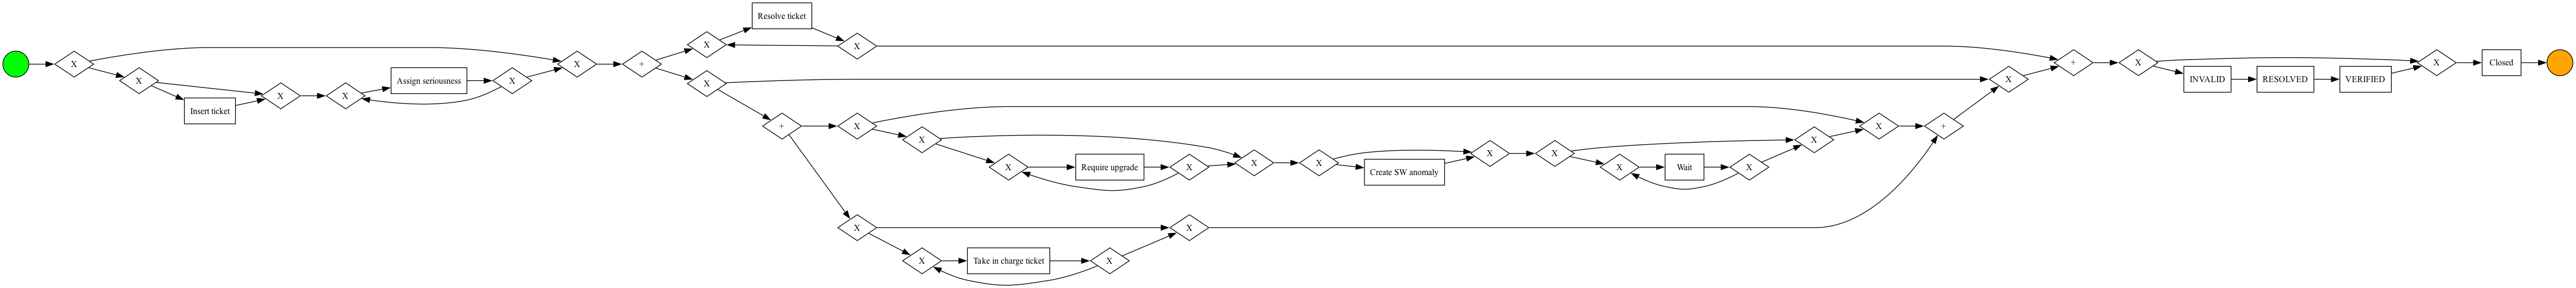

In [5]:
from NeSy4PPM.Data_preprocessing.utils import discover_procedural_model

pm_folder = Path.cwd().parent / 'data' / 'input' / 'petrinets'
process_model = discover_procedural_model(filtered_feedback_path,pm_folder=pm_folder,pm_file_name=f'{log_name}.bpmn')

## 1.4 Extract and encode prefixes

`extract_encode_prefixes` creates one training example for each usable prefix of each training trace. The next activity is the target, and the end-of-trace symbol `!` is used when the trace terminates. Prefixes are padded and encoded according to the selected representation.

This tutorial uses `one-hot` encoding. The function returns `x`, the encoded prefixes; `y_a`, the one-hot next-activity targets; and a third value containing optional resource targets.

In [6]:
from NeSy4PPM.Data_preprocessing.data_preprocessing import extract_encode_prefixes
from NeSy4PPM.Data_preprocessing.utils import Encodings

encoder = Encodings.One_hot
x, y_a, _ = extract_encode_prefixes(log_data,sequences=log_data.training_sequences, encoder=encoder)

Total activities: 14 - Target activities: 15
	 ['Assign seriousness', 'Take in charge ticket', 'Resolve ticket', 'Closed', 'Require upgrade', 'Wait', 'Insert ticket', 'Create SW anomaly', 'Schedule intervention', 'INVALID', 'RESOLVED', 'VERIFIED', 'Resolve SW anomaly', 'DUPLICATE']
Num. of Training sequences: 14989
Num. of features: 14


# 2. Train the neural model

The neural model learns next-activity probabilities from the original training prefixes. `train` builds the selected architecture, creates validation data from the training population, and stores the best checkpoint. The checkpoint is reused for every baseline and for the feedback weight search.

Build model...
Checkpoint path: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk
Checkpoint name pattern: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk/model_{epoch:03d}-{val_loss:.3f}.keras
Epoch 1/200


2026-11-23 18:14:46.854406: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


375/375 - 2s - 4ms/step - loss: 1.2765 - val_loss: 0.5363 - learning_rate: 0.0010
Epoch 2/200
375/375 - 1s - 2ms/step - loss: 0.7328 - val_loss: 0.4752 - learning_rate: 0.0010
Epoch 3/200
375/375 - 1s - 2ms/step - loss: 0.6391 - val_loss: 0.4611 - learning_rate: 0.0010
Epoch 4/200
375/375 - 1s - 2ms/step - loss: 0.6018 - val_loss: 0.4522 - learning_rate: 0.0010
Epoch 5/200
375/375 - 1s - 2ms/step - loss: 0.5743 - val_loss: 0.4499 - learning_rate: 0.0010
Epoch 6/200
375/375 - 1s - 1ms/step - loss: 0.5665 - val_loss: 0.4480 - learning_rate: 0.0010
Epoch 7/200
375/375 - 1s - 2ms/step - loss: 0.5580 - val_loss: 0.4471 - learning_rate: 0.0010
Epoch 8/200
375/375 - 1s - 2ms/step - loss: 0.5532 - val_loss: 0.4461 - learning_rate: 0.0010
Epoch 9/200
375/375 - 1s - 2ms/step - loss: 0.5448 - val_loss: 0.4456 - learning_rate: 0.0010
Epoch 10/200
375/375 - 1s - 2ms/step - loss: 0.5430 - val_loss: 0.4450 - learning_rate: 0.0010
Epoch 11/200
375/375 - 1s - 2ms/step - loss: 0.5364 - val_loss: 0.4425 

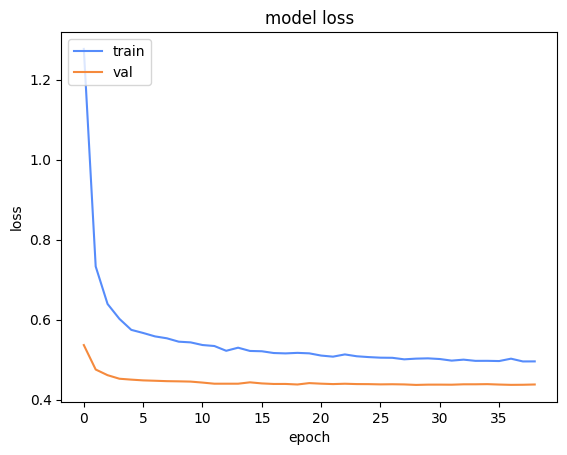

In [11]:
from NeSy4PPM.Data_preprocessing.utils import NN_model
from NeSy4PPM.Training.train_model import train

model = NN_model.Transformer
model_folder = Path.cwd().parent / 'data' / 'output'

train(log_data,model_arch=model,encoder=encoder,output_folder=model_folder,X=x,y_a=y_a)

# 3. Select the modulation weight on feedback data

During beam search, `predict_evaluate` combines the neural next-activity score with the procedural BK score. The weight $w$ controls this balance: $w=0$ gives the neural-only behavior, $w=1$ gives BK-only ranking, and intermediate values combine both sources.

The feedback split is used as a validation set. For every candidate weight, predictions are generated for the same feedback traces and prefix lengths, and the candidate with the highest mean activity Damerau-Levenshtein similarity (DLS) is selected. The chosen value is frozen before any test prediction is generated.

In [8]:
import numpy as np

from NeSy4PPM.Prediction import predict_suffix

prefix_lengths = range(2, 7)
weight_grid = np.round(np.arange(0.0, 1.01, 0.1), 1)
feedback_prediction_filename = f'{log_name}_feedback_prediction.csv'

print(f'Prefix lengths: {list(prefix_lengths)}')
print(f'Candidate weights: {weight_grid.tolist()}')

Prefix lengths: [2, 3, 4, 5, 6]
Candidate weights: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


## 3.1 Generate feedback predictions for the weight grid

Each call appends rows to one feedback-results file. The Weight column records the candidate used for each row, allowing the following cell to compare candidates without rerunning prediction.

In [13]:
for weight in weight_grid:
    for prefix in prefix_lengths:
        predict_suffix.predict_evaluate(log_data, models_folder=model_folder,encoder=encoder,prefix_size=prefix,output_filename=feedback_prediction_filename,
                                        evaluation_trace_ids=log_data.feedback_trace_ids,bk_model=process_model,beam_size=3, weight=float(weight),bk_end=False)

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk/model_029-0.437.keras


  0%|          | 2/457 [00:00<02:43,  2.78it/s]

['Case 1009', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 0.6362810134887695, 21, [], [], [], [], [], [], [], []]
['Case 1036', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Take in charge ticket>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.5, 0.5, 0.0, 0.6362810134887695, 21, [], [], [], [], [], [], [], []]
['Case 1038', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.0, 0.6362810134887695, 21, [], [], [], [], [], [], [], []]
['Case 1039', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.0, 0.6362810134887695, 21, [], [], [], [], [], [], [], []]
['Case 1042', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.0, 0.6362810134887695, 21, [], [], [], [], [], [], [], []]
['Case 105

  3%|▎         | 12/457 [00:01<00:46,  9.66it/s]

['Case 1072', 2, 'Assign seriousness>>Assign seriousness', 'Take in charge ticket>>Resolve ticket>>Closed', 'Take in charge ticket>>Resolve ticket>>Closed', 1.0, 1.0, 0.0, 0.6537699699401855, 30, [], [], [], [], [], [], [], []]
['Case 1086', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.0, 0.6362810134887695, 21, [], [], [], [], [], [], [], []]
['Case 1090', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 1.0, 0.0, 0.6362810134887695, 21, [], [], [], [], [], [], [], []]


  3%|▎         | 15/457 [00:01<00:42, 10.41it/s]

... (1,255 outputs left out)

 65%|██████▌   | 299/457 [00:01<00:00, 189.57it/s]

['Case 3779', 6, 'Assign seriousness>>Take in charge ticket>>Require upgrade>>Require upgrade>>Require upgrade>>Resolve ticket', 'Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed', 0.25, 0.25, 1.0, 0.31503796577453613, 36, [], [], [], [], [], [], [], []]
['Case 3897', 6, 'Assign seriousness>>Take in charge ticket>>Require upgrade>>Create SW anomaly>>Resolve ticket>>INVALID', 'RESOLVED>>VERIFIED>>Closed', 'RESOLVED>>VERIFIED>>Closed', 1.0, 1.0, 1.0, 0.23495221138000488, 24, [], [], [], [], [], [], [], []]


 70%|███████   | 322/457 [00:01<00:00, 166.38it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 457/457 [00:01<00:00, 256.18it/s]

['Case 4395', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed', 0.25, 0.25, 1.0, 0.3016219139099121, 33, [], [], [], [], [], [], [], []]
['Case 4411', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed', 0.25, 0.25, 1.0, 0.3016219139099121, 33, [], [], [], [], [], [], [], []]
['Case 4554', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed', 0.25, 0.25, 1.0, 0.3016219139099121, 33, [], [], [], [], [], [], [], []]


## 3.2 Choose the best weight by feedback DLS

The prediction file already contains one activity-DLS value per feedback trace and prefix. This cell averages those values separately for each candidate, checks that every grid value was evaluated, and selects the largest mean. If candidates tie, the smaller weight is chosen deterministically. The package's evaluation API uses the historical spelling Damerau-Levenshtien; the output column itself is Damerau-Levenshtein Acts.

In [14]:
import pandas as pd

feedback_output_folder = model_folder / 'results' / 'CF'
feedback_prediction_path = feedback_output_folder / feedback_prediction_filename

if not feedback_prediction_path.is_file():
    raise FileNotFoundError(
        f'Feedback predictions were not found at {feedback_prediction_path}. '
        'Run the preceding grid-search cell first.'
    )

feedback_results = pd.read_csv( feedback_prediction_path, delimiter=',',quotechar='|')
required_columns = {'Weight', 'Damerau-Levenshtein Acts'}

feedback_results['Weight'] = pd.to_numeric(feedback_results['Weight'], errors='coerce').round(1)
feedback_results['DLS'] = pd.to_numeric(feedback_results['Damerau-Levenshtein Acts'], errors='coerce')

dls_by_weight = (feedback_results.dropna(subset=['Weight', 'DLS'])
                 .loc[lambda frame: frame['Weight'].isin(weight_grid)]
                 .groupby('Weight', as_index=False)['DLS'].mean()
                 .rename(columns={'DLS': 'mean_DLS'}))

expected_weights = {float(weight) for weight in weight_grid}
observed_weights = set(dls_by_weight['Weight'].astype(float))
missing_weights = sorted(expected_weights - observed_weights)
if missing_weights:
    raise ValueError(
        f'No feedback DLS values were found for weights: {missing_weights}'
    )

ranked_weights = dls_by_weight.sort_values(['mean_DLS', 'Weight'],ascending=[False, True],kind='mergesort')
best_weight = float(ranked_weights.iloc[0]['Weight'])

print(dls_by_weight.sort_values('Weight').round({'mean_DLS': 3}).to_string(index=False))
print(f'Best feedback weight: {best_weight:.1f}')

 Weight  mean_DLS
    0.0     0.909
    0.1     0.909
    0.2     0.909
    0.3     0.909
    0.4     0.909
    0.5     0.909
    0.6     0.911
    0.7     0.912
    0.8     0.912
    0.9     0.936
    1.0     0.123
Best feedback weight: 0.9


# 4. Generate predictions on the held-out test set

The weight has now been selected using feedback traces only. The next cells generate four test-set outputs: a neural-only baseline, a BK-only baseline, post-decoding BK, and decoding-time modulation with the selected `best_weight`.

## 4.1 Neural-only baseline: BS[NN]

This baseline uses beam search with the neural model only. No BK model is supplied and the weight is fixed at zero.

In [15]:
neural_prediction_filename = f'{log_name}_neural_prediction.csv'
for prefix in prefix_lengths:
    predict_suffix.predict_evaluate(log_data,models_folder=model_folder,encoder=encoder,prefix_size=prefix,output_filename=neural_prediction_filename,bk_model=None,beam_size=3,weight=0.0,bk_end=False)

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk/model_029-0.437.keras


  0%|          | 2/917 [00:00<04:10,  3.65it/s]

['Case 1', 2, 'Assign seriousness>>Take in charge ticket', 'Take in charge ticket>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 0.4729280471801758, 21, [], [], [], [], [], [], [], []]
['Case 100', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 0.4729280471801758, 21, [], [], [], [], [], [], [], []]
['Case 1001', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.0, 0.4729280471801758, 21, [], [], [], [], [], [], [], []]
['Case 1007', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.0, 0.4729280471801758, 21, [], [], [], [], [], [], [], []]
['Case 1010', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.66666666666

  1%|          | 9/917 [00:00<01:06, 13.69it/s]

['Case 1023', 2, 'Assign seriousness>>Resolve ticket', 'Resolve ticket>>Closed', 'Closed', 0.5, 0.5, 0.0, 0.2087867259979248, 12, [], [], [], [], [], [], [], []]
['Case 1026', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 0.4729280471801758, 21, [], [], [], [], [], [], [], []]
['Case 1027', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 0.4729280471801758, 21, [], [], [], [], [], [], [], []]
['Case 1043', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 0.4729280471801758, 21, [], [], [], [], [], [], [], []]
['Case 105', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 

  5%|▌         | 50/917 [00:01<00:17, 48.65it/s]

... (305 outputs left out)

 90%|████████▉ | 825/917 [00:12<00:01, 74.25it/s]

['Case 527', 6, 'Assign seriousness>>Wait>>Assign seriousness>>Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.20780301094055176, 12, [], [], [], [], [], [], [], []]
['Case 530', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Wait>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.21544599533081055, 12, [], [], [], [], [], [], [], []]
['Case 532', 6, 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.22424817085266113, 12, [], [], [], [], [], [], [], []]
['Case 566', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.21827411651611328, 12, [], [], [], [], [], [], [], []]
['Case 638', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.21827411651611328, 12, [], [], 

 94%|█████████▍| 863/917 [00:12<00:00, 97.99it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 917/917 [00:12<00:00, 72.12it/s]

['Case 732', 6, 'Assign seriousness>>Create SW anomaly>>Take in charge ticket>>Create SW anomaly>>Require upgrade>>DUPLICATE', 'VERIFIED>>Resolve ticket>>Closed', 'Closed', 0.33333333333333337, 0.33333333333333326, 0.0, 0.2090010643005371, 9, [], [], [], [], [], [], [], []]


## 4.2 BK-only baseline: BS[BK]

This baseline ranks candidates only with the procedural BK by setting $w=1$. The neural model remains available through the checkpoint interface but does not contribute to the beam-search score.

In [16]:
symbolic_prediction_filename = f'{log_name}_symbolic_prediction.csv'
for prefix in prefix_lengths:
    predict_suffix.predict_evaluate(log_data,models_folder=model_folder,encoder=encoder,prefix_size=prefix,output_filename=symbolic_prediction_filename,bk_model=process_model,beam_size=3,weight=1.0,bk_end=False)

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk/model_029-0.437.keras


  0%|          | 2/917 [00:01<09:05,  1.68it/s]

['Case 1', 2, 'Assign seriousness>>Take in charge ticket', 'Take in charge ticket>>Resolve ticket>>Closed', 'Create SW anomaly>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Wait', 0.0714285714285714, 0.19999999999999996, 1.0, 1.1909902095794678, 120, [], [], [], [], [], [], [], []]
['Case 100', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Create SW anomaly>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Wait', 0.0, 0.0, 1.0, 1.1909902095794678, 120, [], [], [], [], [], [], [], []]
['Case 

  1%|          | 9/917 [00:01<02:00,  7.52it/s]

['Case 1023', 2, 'Assign seriousness>>Resolve ticket', 'Resolve ticket>>Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed', 0.25, 0.19999999999999996, 1.0, 0.280181884765625, 33, [], [], [], [], [], [], [], []]
['Case 1026', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Create SW anomaly>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Wait', 0.0, 0.0, 1.0, 1.1909902095794678, 120, [], [], [], [], [], [], [], []]
['Case 1027', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Create SW anomaly>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge ticket>>Take in charge 

  5%|▌         | 50/917 [00:02<00:36, 23.72it/s]

... (303 outputs left out)

 89%|████████▉ | 816/917 [00:15<00:01, 77.67it/s]

['Case 474', 6, 'Assign seriousness>>Assign seriousness>>Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed', 0.25, 0.25, 1.0, 0.3213047981262207, 33, [], [], [], [], [], [], [], []]


 90%|█████████ | 827/917 [00:16<00:01, 57.05it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 917/917 [00:16<00:00, 56.52it/s]

['Case 527', 6, 'Assign seriousness>>Wait>>Assign seriousness>>Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed>>Resolve ticket>>Closed', 0.16666666666666663, 0.19999999999999996, 1.0, 0.5478661060333252, 54, [], [], [], [], [], [], [], []]
['Case 530', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Wait>>Wait>>Resolve ticket', 'Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed', 0.25, 0.25, 1.0, 0.32307004928588867, 33, [], [], [], [], [], [], [], []]
['Case 532', 6, 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed', 0.25, 0.25, 1.0, 0.3507959842681885, 33, [], [], [], [], [], [], [], []]
['Case 566', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'INVALID>>RESOLVED>>VERIFIED>>Closed', 0.25, 0.25, 1.0, 0.3252391815185547, 33, [], [], [], [], [], [], [], []]
['Cas

## 4.3 Post-decoding NeSy baseline: BS[NN] $\rightarrow$ BK

This method performs neural beam search first and applies the procedural BK when choosing the completed suffix by setting $w=0$ and `bk_end=True`

In [9]:
post_decoding_prediction_filename = f'{log_name}_BK_post_prediction.csv'

for prefix in prefix_lengths:
    predict_suffix.predict_evaluate(log_data,models_folder=model_folder,encoder=encoder,prefix_size=prefix,output_filename=post_decoding_prediction_filename,bk_model=process_model,beam_size=3,weight=0.0,bk_end=True)

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk/model_029-0.437.keras


  0%|          | 2/917 [00:01<15:06,  1.01it/s]

['Case 1', 2, 'Assign seriousness>>Take in charge ticket', 'Take in charge ticket>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 1.8942279815673828, 96, [], [], [], [], [], [], [], []]
['Case 100', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 1.8942279815673828, 96, [], [], [], [], [], [], [], []]
['Case 1001', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.0, 1.8942279815673828, 96, [], [], [], [], [], [], [], []]
['Case 1007', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.0, 1.8942279815673828, 96, [], [], [], [], [], [], [], []]
['Case 1010', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.66666666666

  1%|          | 9/917 [00:03<05:28,  2.77it/s]

['Case 1023', 2, 'Assign seriousness>>Resolve ticket', 'Resolve ticket>>Closed', 'Closed', 0.5, 0.5, 0.0, 1.6278202533721924, 93, [], [], [], [], [], [], [], []]
['Case 1026', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 1.8942279815673828, 96, [], [], [], [], [], [], [], []]
['Case 1027', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 1.8942279815673828, 96, [], [], [], [], [], [], [], []]
['Case 1043', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 1.8942279815673828, 96, [], [], [], [], [], [], [], []]
['Case 105', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 

2026-11-23 18:26:23.021753: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
  5%|▌         | 50/917 [00:05<01:12, 11.97it/s]

... (361 outputs left out)

 90%|████████▉ | 821/917 [00:38<00:04, 20.79it/s]

['Case 527', 6, 'Assign seriousness>>Wait>>Assign seriousness>>Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.04360032081604, 66, [], [], [], [], [], [], [], []]
['Case 530', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Wait>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.9858489036560059, 66, [], [], [], [], [], [], [], []]
['Case 532', 6, 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.0673022270202637, 66, [], [], [], [], [], [], [], []]
['Case 566', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.028738021850586, 66, [], [], [], [], [], [], [], []]
['Case 638', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 1.028738021850586, 66, [], [], [], [], [

 94%|█████████▍| 863/917 [00:38<00:01, 29.99it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 917/917 [00:38<00:00, 23.56it/s]

['Case 732', 6, 'Assign seriousness>>Create SW anomaly>>Take in charge ticket>>Create SW anomaly>>Require upgrade>>DUPLICATE', 'VERIFIED>>Resolve ticket>>Closed', 'Closed', 0.33333333333333337, 0.33333333333333326, 0.0, 0.6874208450317383, 48, [], [], [], [], [], [], [], []]


## 4.4 Decoding-time NeSy modulation: BS[NN] ⊗ BK

This method combines the neural and procedural scores during beam search. It uses the `best_weight` selected from feedback DLS and the procedural process_model.

In [12]:
modulation_prediction_filename = f'{log_name}_BK_modulation_prediction.csv'
for prefix in prefix_lengths:
    predict_suffix.predict_evaluate(log_data,models_folder=model_folder,encoder=encoder,prefix_size=prefix,output_filename=modulation_prediction_filename,bk_model=process_model,beam_size=3,weight=best_weight,bk_end=False)

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk/model_029-0.437.keras


  0%|          | 2/917 [00:00<05:00,  3.04it/s]

['Case 1', 2, 'Assign seriousness>>Take in charge ticket', 'Take in charge ticket>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.9, 0.5769228935241699, 21, [], [], [], [], [], [], [], []]
['Case 100', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.9, 0.5769228935241699, 21, [], [], [], [], [], [], [], []]
['Case 1001', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.9, 0.5769228935241699, 21, [], [], [], [], [], [], [], []]
['Case 1007', 2, 'Assign seriousness>>Take in charge ticket', 'Resolve ticket>>Closed', 'Resolve ticket>>Closed', 1.0, 1.0, 0.9, 0.5769228935241699, 21, [], [], [], [], [], [], [], []]
['Case 1010', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.66666666666

  1%|          | 9/917 [00:00<01:25, 10.60it/s]

['Case 1023', 2, 'Assign seriousness>>Resolve ticket', 'Resolve ticket>>Closed', 'Closed', 0.5, 0.5, 0.9, 0.3105900287628174, 12, [], [], [], [], [], [], [], []]
['Case 1026', 2, 'Assign seriousness>>Take in charge ticket', 'Require upgrade>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.9, 0.5769228935241699, 21, [], [], [], [], [], [], [], []]
['Case 1027', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.9, 0.5769228935241699, 21, [], [], [], [], [], [], [], []]
['Case 1043', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.9, 0.5769228935241699, 21, [], [], [], [], [], [], [], []]
['Case 105', 2, 'Assign seriousness>>Take in charge ticket', 'Wait>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.9, 

  5%|▌         | 50/917 [00:01<00:24, 36.08it/s]

... (339 outputs left out)

 89%|████████▉ | 814/917 [00:15<00:01, 78.09it/s]

['Case 474', 6, 'Assign seriousness>>Assign seriousness>>Assign seriousness>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.9, 0.3295321464538574, 12, [], [], [], [], [], [], [], []]


 90%|████████▉ | 823/917 [00:15<00:01, 62.10it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 917/917 [00:15<00:00, 57.64it/s]

['Case 527', 6, 'Assign seriousness>>Wait>>Assign seriousness>>Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.9, 0.37177300453186035, 12, [], [], [], [], [], [], [], []]
['Case 530', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Wait>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.9, 0.3334071636199951, 12, [], [], [], [], [], [], [], []]
['Case 532', 6, 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.9, 0.31490588188171387, 12, [], [], [], [], [], [], [], []]
['Case 566', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.9, 0.3183269500732422, 12, [], [], [], [], [], [], [], []]
['Case 638', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.9, 0.3183269500732422, 12, [], [], [],

## 4.5. Retrain model baseline: BS[NN][Retrain]

This baseline appends the filtered feedback cases to the original training log and trains a new neural model. The retrained checkpoint and prediction results use a separate folder `{log_name}_Retrain`, so they cannot overwrite or be confused with the initial model. The original test split is reused unchanged.

parsing log, completed traces :: 100%|██████████| 917/917 [00:00<00:00, 26131.23it/s]


new activities un-found in the training set ['DUPLICATE']
new activities un-found in the feedback set ['Assign seriousness', 'Take in charge ticket', 'Resolve ticket', 'Closed', 'Require upgrade', 'Wait', 'Insert ticket', 'Create SW anomaly', 'Schedule intervention', 'Resolve SW anomaly', 'DUPLICATE', 'VERIFIED']
Total activities: 14 - Target activities: 15
	 ['Assign seriousness', 'Take in charge ticket', 'Resolve ticket', 'Closed', 'Insert ticket', 'Wait', 'Create SW anomaly', 'Schedule intervention', 'INVALID', 'RESOLVED', 'VERIFIED', 'Resolve SW anomaly', 'Require upgrade', 'DUPLICATE']
Num. of Training sequences: 15713
Num. of features: 14
Build model...
Checkpoint path: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk_Retrain
Checkpoint name pattern: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk_Retrain/model_{epoch:03d}-{val_loss:.3f}.keras
Epoch 1/200


DEBUG:h5py._conv:Creating converter from 5 to 3


393/393 - 2s - 5ms/step - loss: 1.2864 - val_loss: 0.5923 - learning_rate: 0.0010
Epoch 2/200
393/393 - 1s - 1ms/step - loss: 0.7507 - val_loss: 0.4880 - learning_rate: 0.0010
Epoch 3/200
393/393 - 1s - 1ms/step - loss: 0.6424 - val_loss: 0.4835 - learning_rate: 0.0010
Epoch 4/200
393/393 - 1s - 1ms/step - loss: 0.6106 - val_loss: 0.4690 - learning_rate: 0.0010
Epoch 5/200
393/393 - 1s - 1ms/step - loss: 0.5870 - val_loss: 0.4659 - learning_rate: 0.0010
Epoch 6/200
393/393 - 0s - 1ms/step - loss: 0.5794 - val_loss: 0.4675 - learning_rate: 0.0010
Epoch 7/200
393/393 - 0s - 1ms/step - loss: 0.5692 - val_loss: 0.4672 - learning_rate: 0.0010
Epoch 8/200
393/393 - 0s - 1ms/step - loss: 0.5599 - val_loss: 0.4593 - learning_rate: 0.0010
Epoch 9/200
393/393 - 0s - 1ms/step - loss: 0.5533 - val_loss: 0.4577 - learning_rate: 0.0010
Epoch 10/200
393/393 - 0s - 1ms/step - loss: 0.5513 - val_loss: 0.4590 - learning_rate: 0.0010
Epoch 11/200
393/393 - 1s - 1ms/step - loss: 0.5517 - val_loss: 0.4562 

DEBUG:matplotlib.pyplot:Loaded backend module://matplotlib_inline.backend_inline version unknown.
DEBUG:matplotlib.pyplot:Loaded backend module://matplotlib_inline.backend_inline version unknown.
DEBUG:matplotlib.font_manager:findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSerif-BoldItalic.ttf', name='DejaVu Serif', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Oblique.ttf', name='DejaVu Sans', style='oblique', variant='normal', weight=400, stretch='normal', size='scalable')) = 1.05
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='/Users/jamilaoukharijane

Activity Prediction ...
Model filepath: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk_Retrain
Latest checkpoint file: /Users/jamilaoukharijane/Desktop/AdaptiveNeSy4PPM/docs/source/data/output/models/CF/helpdesk_Retrain/model_016-0.452.keras


... (338 outputs left out)

 90%|████████▉ | 824/917 [00:11<00:01, 73.05it/s]

['Case 527_test', 6, 'Assign seriousness>>Wait>>Assign seriousness>>Assign seriousness>>Take in charge ticket>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.21267104148864746, 12, [], [], [], [], [], [], [], []]
['Case 530_test', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Wait>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.22085022926330566, 12, [], [], [], [], [], [], [], []]
['Case 532_test', 6, 'Assign seriousness>>Take in charge ticket>>Resolve ticket>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.21463894844055176, 12, [], [], [], [], [], [], [], []]
['Case 566_test', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.21180081367492676, 12, [], [], [], [], [], [], [], []]
['Case 638_test', 6, 'Assign seriousness>>Take in charge ticket>>Wait>>Take in charge ticket>>Wait>>Resolve ticket', 'Closed', 'Closed', 1.0, 1.0, 0.0, 0.211800

 94%|█████████▍| 861/917 [00:12<00:00, 93.87it/s]/Users/jamilaoukharijane/nesy_env/lib/python3.10/site-packages/tqdm/std.py:917: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 917/917 [00:12<00:00, 75.08it/s]

['Case 732_test', 6, 'Assign seriousness>>Create SW anomaly>>Take in charge ticket>>Create SW anomaly>>Require upgrade>>DUPLICATE', 'VERIFIED>>Resolve ticket>>Closed', 'Resolve ticket>>Closed', 0.6666666666666667, 0.6666666666666666, 0.0, 0.22658896446228027, 15, [], [], [], [], [], [], [], []]


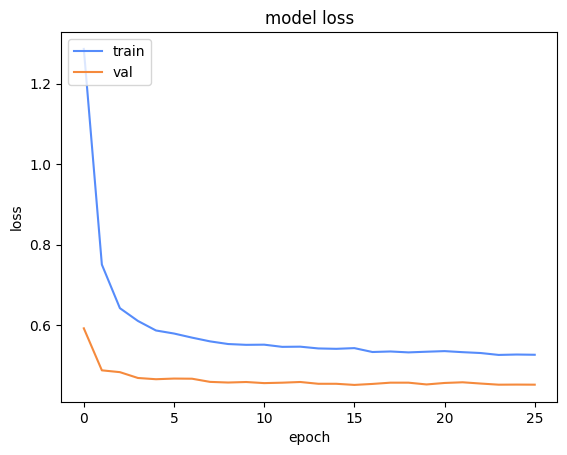

In [9]:
import pandas as pd
import pm4py

train_log = pm4py.read_xes(str(train_log_path))
filtered_feedback_log = pm4py.read_xes(str(filtered_feedback_path))
training_log = pd.concat([train_log, filtered_feedback_log], axis=0, ignore_index=True)

retrain_log_data = LogData(log_path=log_path,log_name=f'{log_name}_Retrain',train_log=training_log,test_log=f'{log_name}_test.xes')
retrain_x, retrain_y_a, _ = extract_encode_prefixes(retrain_log_data,sequences=retrain_log_data.training_sequences,encoder=encoder)

train(retrain_log_data,model_arch=model,encoder=encoder,output_folder=model_folder,X=retrain_x,y_a=retrain_y_a)

retrain_prediction_filename = f'{log_name}_retrain_prediction.csv'
for prefix in prefix_lengths:
    predict_suffix.predict_evaluate(retrain_log_data,models_folder=model_folder,encoder=encoder,prefix_size=prefix,output_filename=retrain_prediction_filename,bk_model=None,beam_size=3,weight=0.0,bk_end=False)

# 5. Evaluate compared methods on the test set

The held-out evaluation reports mean prediction time, activity DLS, and token-based-replay fitness. The same discovered process model is used to measure fitness for every method, including the neural-only baseline.

In [12]:
from NeSy4PPM.Evaluation import evaluate_all

metrics = ['Time', 'Damerau-Levenshtien similarity', 'Fitness']
test_output_folder = model_folder / 'results' / 'CF'
test_prediction_files = {
    'neural': neural_prediction_filename,
    'symbolic': symbolic_prediction_filename,
    'BK_post': post_decoding_prediction_filename,
    'BK_modulation': modulation_prediction_filename,
    'Retrain':retrain_prediction_filename
}

initial_test_results = {}
for method, prediction_filename in test_prediction_files.items():
    initial_test_results[method] = evaluate_all(log_data=log_data,output_folder=test_output_folder,filename=prediction_filename,metrics=metrics,petri_net_model=process_model,)
    result = initial_test_results[method]
    print(f'Method: {method}')
    print(f"  Time: {result['Time']}")
    print(
        '  Activity DLS: '
        f"{result['Damerau-Levenshtien similarity']['Activities']}"
    )
    print(f"  Fitness: {result['Fitness']}")
    print()

replaying log with TBR, completed traces :: 100%|██████████| 145/145 [00:00<00:00, 2391.44it/s]


Method: neural
  Time: 0.388
  Activity DLS: 0.786
  Fitness: 0.9947461813775105



replaying log with TBR, completed traces :: 100%|██████████| 170/170 [00:00<00:00, 1564.59it/s]


Method: symbolic
  Time: 0.822
  Activity DLS: 0.104
  Fitness: 0.9662540446774122



replaying log with TBR, completed traces :: 100%|██████████| 141/141 [00:00<00:00, 2368.68it/s]


Method: BK_post
  Time: 1.578
  Activity DLS: 0.799
  Fitness: 0.9974803994421347



replaying log with TBR, completed traces :: 100%|██████████| 125/125 [00:00<00:00, 2449.23it/s]


Method: BK_modulation
  Time: 0.491
  Activity DLS: 0.847
  Fitness: 0.9982038919586487



replaying log with TBR, completed traces :: 100%|██████████| 131/131 [00:00<00:00, 2566.51it/s]

Method: Retrain
  Time: 0.357
  Activity DLS: 0.843
  Fitness: 0.9983349718811341

